In [2]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '6aad58d1'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to 'e618af84'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to '131bd94c'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

https://github.com/cllorey/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [3]:
# FINAL CODE

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

### NYSDEC Spill Incidents: 
Under New York State law and regulations, spills that could pollute the lands or waters of the state must be reported by the spiller. This dataset comes from the New York State Department of Environmental Conservation and contains records of spills of petroleum and other hazardous materials in New York State. Retrieved November 7, 2026 from: [https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data)

### 2026 counties (and equivalent) TIGER shapefile: 
The 2026 TIGER/Line Shapefiles are from the US Census Bureau and reflect available governmental unit boundaries of county and county-equivalent entities as reported to the 2026 Boundary and Annexation Survey through March 1, 2026. Retrieved November 7, 2026 from: [https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html)

## 3. Import libraries

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [5]:
# Import data
fp = os.path.join('data','Spill_Incidents_20261103.csv')
spills = pd.read_csv(fp)

fp = os.path.join('data','tl_2026_us_county','tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [6]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [7]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [8]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [9]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

In [10]:
# Look at unique values in the DEC Region column
spills['DEC Region'].unique()

array([3, 2, 7, 5, 9, 1, 6, 4, 8])

In [11]:
# Look at null values in the dataframe
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574758 entries, 0 to 574757
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Spill Number           574758 non-null  int64 
 1   Program Facility Name  574752 non-null  object
 2   Street 1               574624 non-null  object
 3   Street 2               44737 non-null   object
 4   Locality               573607 non-null  object
 5   County                 574758 non-null  object
 6   ZIP Code               57918 non-null   object
 7   SWIS Code              574758 non-null  int64 
 8   DEC Region             574758 non-null  int64 
 9   Spill Date             574607 non-null  object
 10  Received Date          574255 non-null  object
 11  Contributing Factor    574758 non-null  object
 12  Waterbody              47992 non-null   object
 13  Source                 574758 non-null  object
 14  Close Date             562343 non-null  object
 15  

From this data exploration, it is apparent that the 'County' column needs to be cleaned in order to be workable, or the 'DEC Region' or 'SWIS' column should be used instead depending on the analysis. Many of the values in the 'County' column list region information instead of specifying county information (region information is supposed to be in the DEC region column). It also appears that counties outside of New York State are included. Certain columns should be converted from objects to int64 or to datetimes. 

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [12]:
# Simplify column names by making them all lowercase and replacing spaces with underscores
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [13]:
# Change the data type of the `spill_date`, `received_date`, and `close_date` columns to datetimes
for col in ['spill_date', 'received_date', 'close_date']:
    spills[col] = pd.to_datetime(spills[col])


In [14]:
# Remove commas and change the data type of the `quantity` and `recovered` columns to floats
for col in ['quantity', 'recovered']:
    spills[col] = spills[col].str.replace(',','').astype('float')

In [15]:
# Verify dtypes
spills.dtypes

spill_number                      int64
program_facility_name            object
street_1                         object
street_2                         object
locality                         object
county                           object
zip_code                         object
swis_code                         int64
dec_region                        int64
spill_date               datetime64[ns]
received_date            datetime64[ns]
contributing_factor              object
waterbody                        object
source                           object
close_date               datetime64[ns]
material_name                    object
material_family                  object
quantity                        float64
units                            object
recovered                       float64
dtype: object

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [16]:
# Select petroleum spills between January 1, 2023 and December 31, 2023
petr_23 = spills[(spills['spill_date'] >= '01/01/2023') & (spills['spill_date'] <= '12/31/2023') & (spills['material_family'] == 'Petroleum')]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [17]:
# Verify that petr_23 only contains spills from 2023
if petr_23['spill_date'].dt.year.unique() != 2023:
    print(f"petr_23 contains data from {petr_23['spill_date'].dt.year.unique()}")
else:
    print("petr_23 only contains data from 2023")

petr_23 only contains data from 2023


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [18]:
# Determine if 'petr_23' only has data for petroleum spills
assert (petr_23['material_family'] == 'Petroleum').all(), "petr_23 contains data for non-petroleum materials"


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

These numbers are not the same, as there are duplicates in the 'spill_number' column for spills with multiple materials, which leads to fewer unique values. This is referenced in the data overview, where it states that rows with the same spill number will occur for spills with multiple materials. 

In [19]:
# Print the number of rows in `petr_23` and number of unique spills in 'spill_number'
if len(petr_23) == petr_23['spill_number'].nunique():
    print("petr_23 has as many rows as it does unique values of 'spill_number'")
else:
    print(f"petr_23 has {len(petr_23)} rows while the 'spill_number' column has {petr_23['spill_number'].nunique()} unique values")

petr_23 has 8468 rows while the 'spill_number' column has 8228 unique values


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [20]:
# Group by spills per county 
spills_per_county = petr_23.groupby('county')['spill_number'].nunique()

spills_per_county = spills_per_county.reset_index()
spills_per_county = spills_per_county.rename(columns={'spill_number':'n_spills'})
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [21]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [22]:
# Check the dataframe's head
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [23]:
# Check the data types of the columns
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [24]:
# Check the crs
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [25]:
# Plot the geo-dataframe
counties.plot()

<Axes: >

This dataframe contains county boundaries across the entire US, including those outside the contiguous US. The CRS is 4269. Most data types are objects, with the exception of the geometries and the land and water area columns (ALAND, AWATER, respectively)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

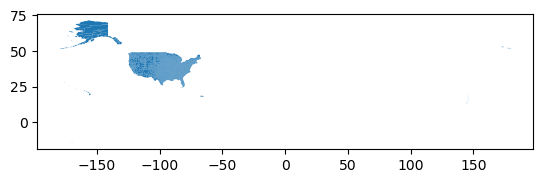

In [26]:
# Simplify column names by making them all lowercase
counties.columns = counties.columns.str.lower()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [27]:
# Select all rows where 'statefp' is 36 (the FIPS code for New York)
ny_counties = counties[counties['statefp'] == '36'].copy()

<Axes: >

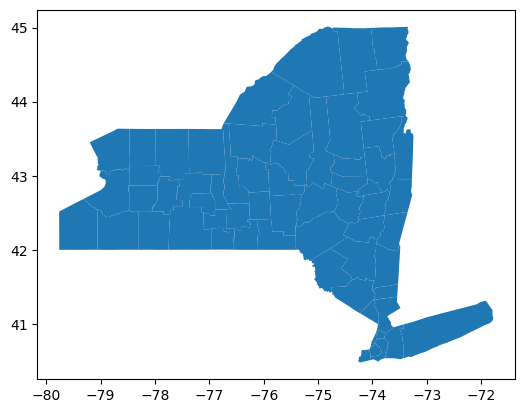

In [28]:
# Plot the ny_counties df
ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [29]:
# Print the unique names of counties in `ny_counties`
ny_counties['name'].unique()

array(['Erie', 'Niagara', 'Jefferson', 'Steuben', 'Seneca', 'Rensselaer',
       'Albany', 'Saratoga', 'Schoharie', 'Schenectady', 'Ulster',
       'Dutchess', 'Orange', 'Columbia', 'Tompkins', 'Tioga', 'Broome',
       'Cayuga', 'Genesee', 'Onondaga', 'Oswego', 'Madison', 'Livingston',
       'Monroe', 'Ontario', 'Orleans', 'Wayne', 'Chautauqua', 'Sullivan',
       'Chemung', 'Cattaraugus', 'Fulton', 'Montgomery', 'Cortland',
       'Warren', 'Washington', 'Otsego', 'Queens', 'Bronx', 'Nassau',
       'Westchester', 'Richmond', 'Kings', 'Suffolk', 'Rockland',
       'New York', 'Putnam', 'Clinton', 'St. Lawrence', 'Herkimer',
       'Oneida', 'Yates', 'Greene', 'Schuyler', 'Delaware', 'Hamilton',
       'Lewis', 'Allegany', 'Chenango', 'Wyoming', 'Franklin', 'Essex'],
      dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [30]:
# Print the unique names of counties in `spills_per_county`
spills_per_county['county'].unique()

array(['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga',
       'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia',
       'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin',
       'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson',
       'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery',
       'Nassau', 'New Jersey - Region 2', 'New York', 'Niagara', 'Oneida',
       'Onondaga', 'Onondaga Indian Reservation', 'Ontario', 'Orange',
       'Orleans', 'Oswego', 'Otsego', 'Pennsylvania - Region 3', 'Putnam',
       'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga',
       'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St Lawrence',
       'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins',
       'Tuscarora Indian Reservation', 'Ulster', 'Warren', 'Washington',
       'Wayne', 'Westchester', 'Wyoming', 'Yates'], dtype=object)

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [31]:
# Determine the names of counties in spills_per_county and not ny_counties 
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_counties['name'])
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [32]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [33]:
# Determine the names of counties in ny_counties and not spills_per_county
diff_names_ny = np.setdiff1d(ny_counties['name'], spills_per_county['county'])
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [34]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [35]:
# Locate the number of spills in 'Tuscarora Indian Reservation' and 'Onondaga Indian Reservation' (using .item() to isolate the count)
for res in ['Tuscarora Indian Reservation', 'Onondaga Indian Reservation']:
    n = spills_per_county.loc[spills_per_county['county'] == res, 'n_spills'].item()
    print(f"The number of spills in {res} is {n}")


The number of spills in Tuscarora Indian Reservation is 2
The number of spills in Onondaga Indian Reservation is 1


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [36]:
# Replace 'St Lawrence' with 'St. Lawrence'
spills_per_county['county'] = spills_per_county['county'].str.replace('St Lawrence', 'St. Lawrence')

In [37]:
# Verify that the change was made
assert (spills_per_county['county'] == 'St. Lawrence').any(), "'St. Lawrence' not found'"
assert not (spills_per_county['county'] == 'St Lawrence').any(), "'St Lawrence' still present'"

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [38]:
# Change `ny_counties` 'name' column to 'county' so it can be joined with `spills_per_county`
ny_counties = ny_counties.rename(columns={'name':'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [39]:
ny_spills = pd.merge(ny_counties, spills_per_county, on='county', how='inner')

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [40]:
# Determine what rows were dropped from the inner join
np.setdiff1d(spills_per_county['county'], ny_spills['county'])

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'Tuscarora Indian Reservation'],
      dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Yes, dropping these records would impact the map/information we report as it would leave out spill data for the Onondaga Indian Reservation and the Tuscarora Indian Reservation, both of which are in NY. Dropping the New Jersey and Pennsylvania counties is okay, as they are not in New York and wouldn't be represented in our map. 

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [41]:
# Record initial spill count in Niagara county (using .item() to isolate the count) 
before_tusc = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'].item()
print(before_tusc)

# Add the two Tuscarora Indian Reservation spills to Niagara county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += 2 # += updates the df

# Record new spill count in Niagara 
after_tusc = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'].item()
print(after_tusc)

# Verify that the dataframe was updated
assert after_tusc == before_tusc + 2, f"{before_tusc + 2} does not equal {after_tusc}"



97
99


In [42]:
# Record initial spill count in Onondaga county (using .item() to isolate the count) 
before_onon = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'].item()
print(before_onon)

# Add the one Onondaga Indian Reservation spill to Onondaga county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += 1 # += updates the df

# Record new spill count in Onondaga 
after_onon = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'].item()
print(after_onon)

# Verify that the dataframe was updated
assert after_onon == before_onon + 1, f"{before_onon + 1} does not equal {after_onon}"

214
215


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



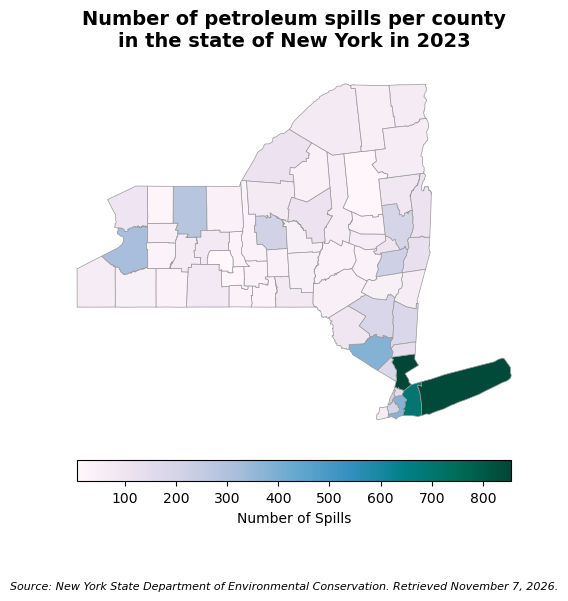

In [43]:
# Initialize empty plot
fig, ax = plt.subplots(figsize=(8, 6))

# Remove the axis for a cleaner map
ax.axis('off')

# Create choropleth map of spills per county in NY in 2023
# Plot with refined color and edge style
ny_spills.plot(
    ax=ax,
    column='n_spills', # Indicates which column to color by
    cmap='PuBuGn',
    legend=True,
    edgecolor="0.6",
    linewidth=0.5,
    legend_kwds={
        "shrink": 0.7,
        "label": "Number of Spills",
        "orientation": "horizontal",
        "pad": 0.05
    }
)

# Add title for better context
ax.set_title('Number of petroleum spills per county\nin the state of New York in 2023',
             fontsize=14, weight='bold', pad=15)

# Add caption below the plot
fig.text(
    0.5,
    0.01,
    "Source: New York State Department of Environmental Conservation. Retrieved November 7, 2026.", 
    ha="center",
    fontsize=8, 
    style="italic",
    wrap=True
)

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

In [ ]:
# Look at the three counties with the most spills in 2023
ny_spills.sort_values(by='n_spills', ascending=False).head(3)

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
40,36,119,00974157,36119,0500000US36119,Westchester,Westchester County,06,H1,G4020,408,35620,35614,A,1115811923,179391712,+41.1526862,-073.7457526,"POLYGON ((-73.65762 40.98550, -73.65739 40.985...",855
43,36,103,00974149,36103,0500000US36103,Suffolk,Suffolk County,06,H1,G4020,408,35620,35004,A,2359209021,3787486264,+40.9435540,-072.6922183,"POLYGON ((-71.80938 41.20323, -71.79115 41.184...",845
39,36,059,00974128,36059,0500000US36059,Nassau,Nassau County,06,H1,G4020,408,35620,35004,A,736965427,437285877,+40.7295039,-073.5894030,"POLYGON ((-73.78019 40.82640, -73.77498 40.830...",698


This map was created by cleaning and combining spill data from the New York State Department of Environmental Conservation (NYSDEC) with US Census Bureau county boundary data. The map shows that the counties with the highest number of spills are centered in the southeast corner of the state. In particular, the three counties with the largest number of spills in 2023 were Westchester, Suffolk, and Nassau.

Notably, in cleaning our data, we lost and had to re-add spill data for the Tuscarora and Onondaga Indian Reservations, as they are listed as their own separate counties for NYSDEC data collection purposes but are lumped in with the larger Niagara and Onondaga counties, respectively, in the US Census Bureau. While their specific geometries are not reflected on the map as a result of the Census Bureau county-level data not including geographic information on reservations, their spills are included in the total count for the  respective counties. In line with CARE Principals for Indigenous Data Governance, it would be irresponsible to exclude reservation data from this dataset just because they were not included in the US Census Bureau. A better version of this map would also include reservation geometries so that users from either of these reservations can easily access the information about their area instead of the larger county. 

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.